In [ ]:
!pip install catboost

In [ ]:
#pip install catboost
import catboost as cat
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_score

In [ ]:
arr = np.load('/content/drive/MyDrive/Colab Notebooks/gaussian.npz')
x = arr['x']
y = arr['y']

model  = cat.CatBoostClassifier(learning_rate=0.1, max_depth=3, n_estimators=100).fit(x,y)
score = cross_val_score(model,x,y,cv=5)
print(f'CAT BOOST SCORE : {score.mean():.2f}') # 0.86

In [ ]:
def draw_area(x,y,model):
  # 1. 그래프의 x,y 축의 범위 설정
  x_min,x_max = x[:,0].min()-1, x[:,0].max()+1
  y_min,y_max = x[:,1].min()-1, x[:,1].max()+1

  # 2. 만든 범위를 0.01 간격으로 촘촘한 값을 생성
  pos_x = np.arange(x_min,x_max,0.01)
  pos_y = np.arange(y_min,y_max,0.01)
  # print(f'pos X : {pos_x}')
  # print(f'pos Y : {pos_y}')

  # 3. 격자 형태로 x,y 배열을 만든다.
  xx,yy = np.meshgrid(pos_x, pos_y)

  # 4. 두 배열을 합쳐서 일렬로 만들어 준다.
  # 두 배열을 합칠때 각각 1차원 이어야 하는데 xx, yy 는 2차원이다.
  # 그래서 ravel() 함수를 통해 1차원으로 만든다.
  val = np.c_[xx.ravel(),yy.ravel()]
  # print(val) # [[x,y],[x,y],...]

  # 5. 이렇게 생성된 값으로 모델에 예측을 시킨다.
  z = model.predict(val)
  print(z)

  # 6. 영역을 그려준다.
  plt.scatter(x[:,0],x[:,1], c=y)
  plt.contourf(xx,yy,z.reshape(xx.shape),alpha=0.3)
  plt.show()

[1 1 1 ... 0 0 0]


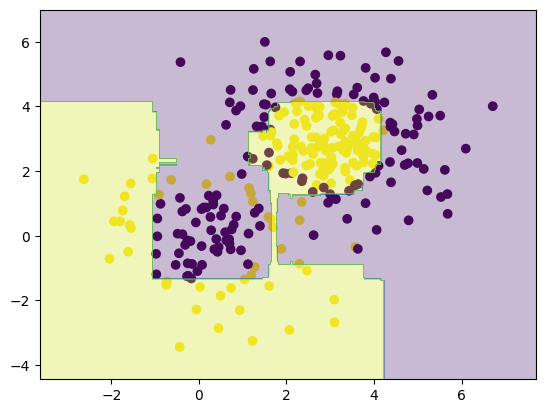

In [ ]:
draw_area(x,y,model)